# Chapter 5: Why the boring model often ships

*When the simpler model wins · also searched as: model selection, Occam's razor machine learning,
interpretable vs black box*

**By the end you can** run the two tests a complex model must pass (is the gap real, is it worth it),
find the break-even in rupees, and state the flip. Model scores below are invented except where a
source is named.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


## Predict first

A simple model and a complex one, on the same five folds. The complex one has the higher mean. Does it
ship?

means: simple 0.794, complex 0.802
complex minus simple, fold by fold: [0.01 0.   0.01 0.01 0.01]


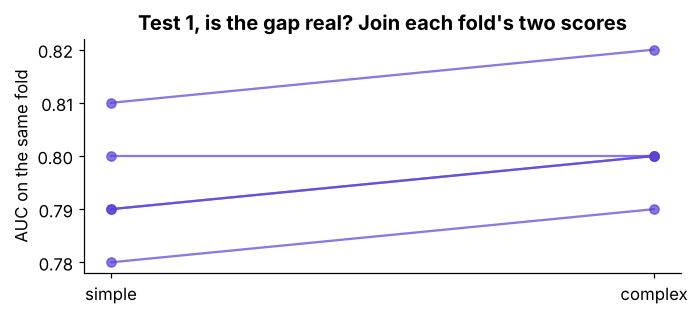

In [2]:
import numpy as np, pandas as pd
# Invented AUCs on the same five folds.
simple = np.array([0.78, 0.80, 0.79, 0.81, 0.79])
complex_ = np.array([0.79, 0.80, 0.80, 0.82, 0.80])
paired = complex_ - simple
print(f"means: simple {simple.mean():.3f}, complex {complex_.mean():.3f}")
print("complex minus simple, fold by fold:", paired.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3))
for i in range(5):
    ax.plot([0, 1], [simple[i], complex_[i]], "o-", color=VIOLET, alpha=0.7)
ax.set_xticks([0, 1]); ax.set_xticklabels(["simple", "complex"]); ax.set_ylabel("AUC on the same fold")
ax.set_title("Test 1, is the gap real? Join each fold's two scores"); plt.tight_layout(); plt.show()

Test 1 says the gap is real when the complex model wins fold after fold. Test 2 asks whether it is
worth having, and that answer is in rupees.

In [3]:
def ships(extra_buyers_low, margin_rs, extra_cost_rs):
    """The complex model ships when its low-end gain beats what it costs to run and explain."""
    return extra_buyers_low * margin_rs > extra_cost_rs

# Invented: the complex model finds 30 to 70 extra buyers per campaign, Rs 1,200 margin each,
# and costs Rs 60,000 more per campaign to run, monitor and explain.
low, high, margin, extra = 30, 70, 1200, 60_000
print(f"gain Rs {low * margin:,} to Rs {high * margin:,}; extra cost Rs {extra:,}")
print(f"break-even: {extra / margin:.0f} extra buyers at the low end")
print("ships?", ships(low, margin, extra))
check("the rule reads the low end, so a wide range cannot sneak a model through", not ships(low, margin, extra))
check("and the same model ships once its extra cost falls below the low-end gain", ships(low, margin, 30_000))

gain Rs 36,000 to Rs 84,000; extra cost Rs 60,000
break-even: 50 extra buyers at the low end
ships? False
PASS  the rule reads the low end, so a wide range cannot sneak a model through
PASS  and the same model ships once its extra cost falls below the low-end gain


## A case where the simpler model shipped: pneumonia risk

In the 1990s a neural net scored AUC 0.86 against logistic regression's 0.77 on pneumonia risk. A rule
learner on the same data found "asthma lowers risk", because asthmatics were sent straight to
intensive care and so died less. The team went forward only with models they could read, even at
lower AUC. On the 2015 data the readable model sat within 0.02 of the black boxes (Caruana and others,
KDD 2015, verified 28 October 2026).

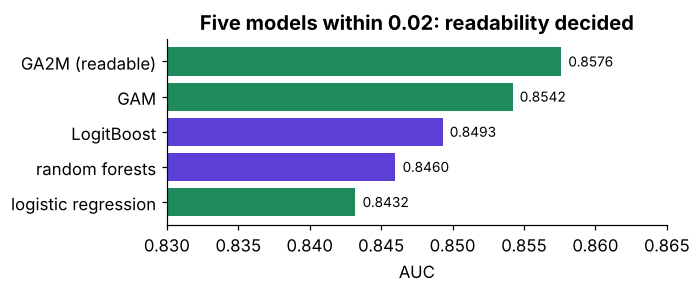

PASS  the published models sit within 0.02 AUC


In [4]:
# AUCs as published in Caruana and others, KDD 2015, pneumonia data (14,199 patients).
paper = pd.Series({"logistic regression": 0.8432, "random forests": 0.8460, "LogitBoost": 0.8493,
                   "GAM": 0.8542, "GA2M (readable)": 0.8576})
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(paper.index, paper.values, color=[GREEN, VIOLET, VIOLET, GREEN, GREEN])
for i, v in enumerate(paper.values):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0.83, 0.865); ax.set_xlabel("AUC")
ax.set_title("Five models within 0.02: readability decided"); plt.tight_layout(); plt.show()
check("the published models sit within 0.02 AUC", paper.max() - paper.min() < 0.02)

## Carry this: the flip, said both ways

| The simpler model ships when | The complex model ships when |
|---|---|
| its gap to the complex one is not real across folds | it wins fold after fold |
| the complex model's low-end gain is below its extra cost | its low-end gain clears the extra cost |
| a committee, a regulator or a doctor must read and repair it | the decision needs an interaction only it captures, and someone owns its monitoring |

Case 3 runs both tests on the bank's file with Kalpa's Rs 40 nudge and Rs 1,200 margin.